# Praktikum Data Mining: Preprocessing 
Nama: Fahmi Alfayadh \
NRP: 5054251015\
Kelas: Data Mining (N)

## 1. Load Data dan Eksplorasi Awal
Pemeriksaan struktur kolom, tipe data, serta nilai statistik ringkasan awal.


In [74]:
import pandas as pd

# Load dataset
df = pd.read_csv('5054251015_Fahmi Alfayadh_tugas_praproses_data.csv')
df.head()


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [75]:
# Informasi tipe data dan jumlah nilai non-null
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [76]:
# Statistik deskriptif fitur numerik
df.describe().round(2)


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.00,1460.0,1201.00,1460.00,1460.00,1460.00,1460.00,1460.00,1452.00,1460.00,...,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.0
mean,730.50,56.9,70.05,10516.83,6.10,5.58,1971.27,1984.87,103.69,443.64,...,94.24,46.66,21.95,3.41,15.06,2.76,43.49,6.32,2007.82,180921.2
std,421.61,42.3,24.28,9981.26,1.38,1.11,30.20,20.65,181.07,456.10,...,125.34,66.26,61.12,29.32,55.76,40.18,496.12,2.70,1.33,79442.5
min,1.00,20.0,21.00,1300.00,1.00,1.00,1872.00,1950.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,2006.00,34900.0
25%,365.75,20.0,59.00,7553.50,5.00,5.00,1954.00,1967.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,5.00,2007.00,129975.0
50%,730.50,50.0,69.00,9478.50,6.00,5.00,1973.00,1994.00,0.00,383.50,...,0.00,25.00,0.00,0.00,0.00,0.00,0.00,6.00,2008.00,163000.0
75%,1095.25,70.0,80.00,11601.50,7.00,6.00,2000.00,2004.00,166.00,712.25,...,168.00,68.00,0.00,0.00,0.00,0.00,0.00,8.00,2009.00,214000.0
max,1460.00,190.0,313.00,215245.00,10.00,9.00,2010.00,2010.00,1600.00,5644.00,...,857.00,547.00,552.00,508.00,480.00,738.00,15500.00,12.00,2010.00,755000.0


In [77]:
# Pemeriksaan baris duplikat dan total missing values awal
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Total missing values: {df.isnull().sum().sum()}")

# Seluruh kolom yang memiliki missing values
df.isnull().sum()[df.isnull().sum() > 0].sort_values(ascending=False)


Duplicate rows: 0
Total missing values: 7829


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

## 2. Penanganan Missing Values
Berdasarkan dokumentasi `data_description.txt`, sebagian besar nilai NA pada fitur fasilitas merepresentasikan ketiadaan fasilitas (None), bukan data hilang akibat kesalahan input.


In [78]:
import pandas as pd
import numpy as np

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

info_missing_values = pd.DataFrame({
    'missing_values': missing,
    'jenis_fitur': [
        'numerik' if pd.api.types.is_numeric_dtype(df[col])
        else 'kategorikal'
        for col in missing.index
    ],
    'tipe_missing': [
        'NaN' if df.loc[df[col].isna(), col].map(
            lambda x: isinstance(x, float) and np.isnan(x)
        ).any()
        else 'NA/None'
        for col in missing.index
    ]
})

info_missing_values

,missing_values,jenis_fitur,tipe_missing
PoolQC,1453,kategorikal,NaN
MiscFeature,1406,kategorikal,NaN
Alley,1369,kategorikal,NaN
Fence,1179,kategorikal,NaN
MasVnrType,872,kategorikal,NaN
FireplaceQu,690,kategorikal,NaN
LotFrontage,259,numerik,NaN
GarageType,81,kategorikal,NaN
GarageYrBlt,81,numerik,NaN
GarageFinish,81,kategorikal,NaN


In [79]:
# Verifikasi hubungan ketiadaan kolam (PoolArea == 0) dengan status PoolQC
print(f"Total PoolArea bernilai 0: {df[df['PoolArea'] == 0].shape[0]}")
print(f"Total PoolQC bernilai NaN: {df['PoolQC'].isnull().sum()}")


Total PoolArea bernilai 0: 1453
Total PoolQC bernilai NaN: 1453


In [80]:
# 1. Fitur kategorikal fasilitas: NA diisi 'None' (tidak memiliki fasilitas)
none_cols = [
    'PoolQC', 'MiscFeature', 'Alley', 'Fence', 'MasVnrType', 'GarageType',
    'FireplaceQu', 'GarageFinish', 'GarageQual', 'GarageCond',
    'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2'
]
df[none_cols] = df[none_cols].fillna('None')

# 2. Fitur kategorikal data hilang tunggal: diisi dengan modus
df['Electrical'] = df['Electrical'].fillna(df['Electrical'].mode()[0])

# 3. Fitur numerik terkait ketiadaan fasilitas: diisi 0 atau tahun bangun rumah
df['MasVnrArea'] = df['MasVnrArea'].fillna(0)
df['GarageYrBlt'] = df['GarageYrBlt'].fillna(df['YearBuilt'])

# 4. Fitur numerik LotFrontage: diisi dengan median berdasarkan Neighborhood
df['LotFrontage'] = df.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.median()))

# Verifikasi total missing values tersisa
print(f"Total missing values tersisa: {df.isnull().sum().sum()}")


Total missing values tersisa: 0


In [81]:
import seaborn as sns
import matplotlib.pyplot as plt

## 3. Deteksi dan Penanganan Outlier
Deteksi outlier menggunakan metode IQR pada seluruh fitur numerik, dilanjutkan visualisasi scatter plot untuk identifikasi titik anomali.


In [82]:
# Deteksi outlier IQR pada seluruh fitur numerik
import numpy as np

numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns.drop('Id')

info_outlier = pd.DataFrame(columns=['fitur', 'batas_bawah', 'batas_atas', 'jumlah_outlier'])

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_outlier = ((df[col] < lower) | (df[col] > upper)).sum()
    
    new_row = pd.DataFrame({
        'fitur': [col],
        'batas_bawah': [lower],
        'batas_atas': [upper],
        'jumlah_outlier': [n_outlier]
    })

    if n_outlier > 0:
        info_outlier = pd.concat([info_outlier, new_row], ignore_index=True)

display(info_outlier.sort_values(by='jumlah_outlier', ascending=False))

,fitur,batas_bawah,batas_atas,jumlah_outlier
26,EnclosedPorch,0.0,0.0,208
8,BsmtFinSF2,0.0,0.0,167
4,OverallCond,3.5,7.5,125
28,ScreenPorch,0.0,0.0,116
0,MSSubClass,-55.0,145.0,103
6,MasVnrArea,-246.375,410.625,98
1,LotFrontage,30.0,110.0,93
16,BsmtHalfBath,0.0,0.0,82
25,OpenPorchSF,-102.0,170.0,77
2,LotArea,1481.5,17673.5,69


4 fitur dengan korelasi tertinggi: ['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea']


/tmp/ipykernel_44918/2971724858.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col], vert=True)
/tmp/ipykernel_44918/2971724858.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col], vert=True)
/tmp/ipykernel_44918/2971724858.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col], vert=True)
/tmp/ipykernel_44918/2971724858.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col], vert=True)


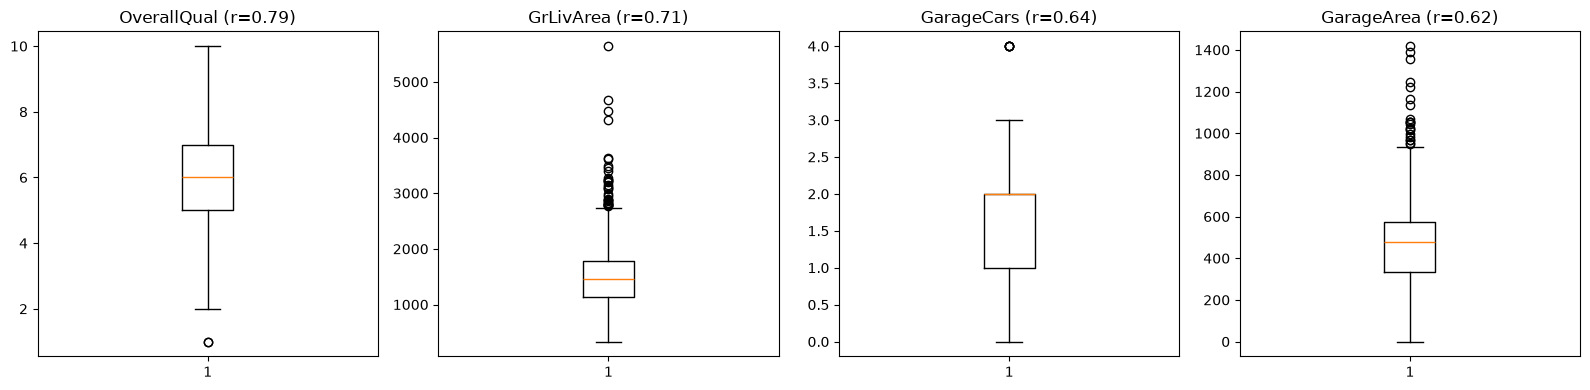

In [83]:
# Boxplot fitur numerik dengan korelasi tertinggi terhadap SalePrice
top_corr = df.select_dtypes(include=['int64', 'float64']).corr()['SalePrice'].abs().sort_values(ascending=False)
top_features = top_corr[1:5].index.tolist()  # 4 fitur teratas (skip SalePrice)
print(f"4 fitur dengan korelasi tertinggi: {top_features}")

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, top_features):
    ax.boxplot(df[col], vert=True)
    ax.set_title(f'{col} (r={top_corr[col]:.2f})')
plt.tight_layout()
plt.show()


4 fitur dengan outlier terbanyak: ['EnclosedPorch', 'BsmtFinSF2', 'OverallCond', 'ScreenPorch', 'MSSubClass']


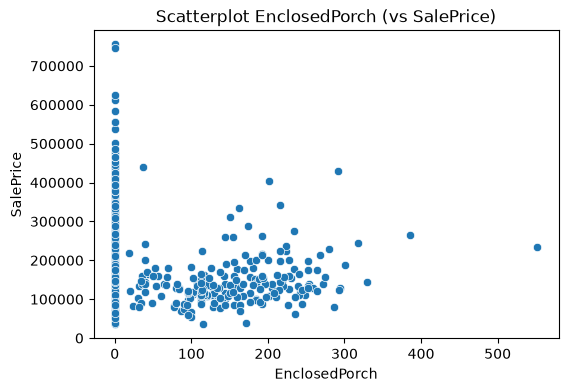

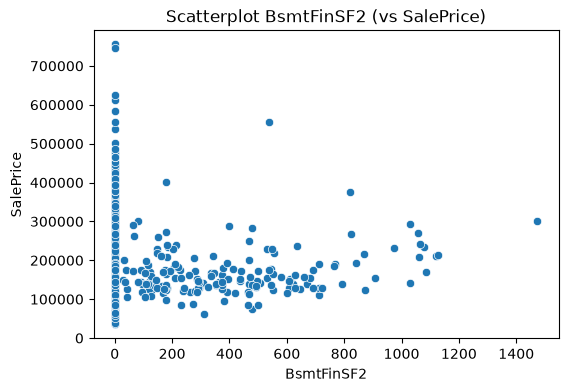

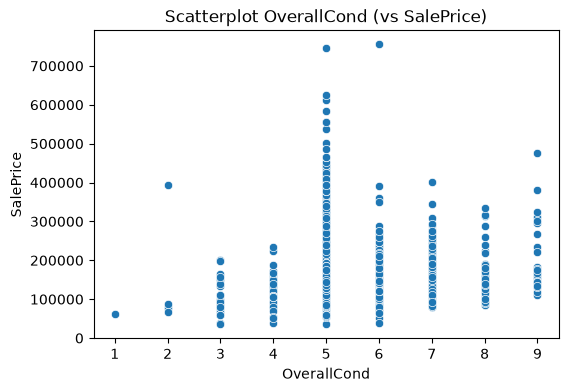

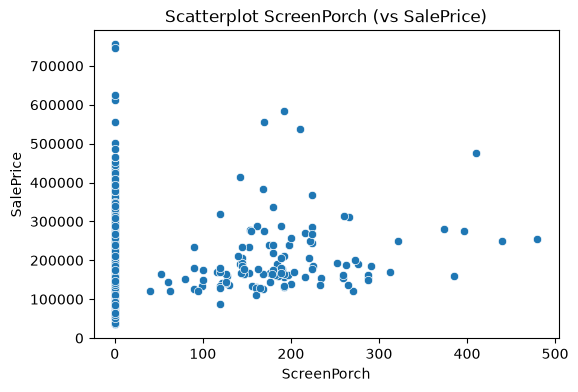

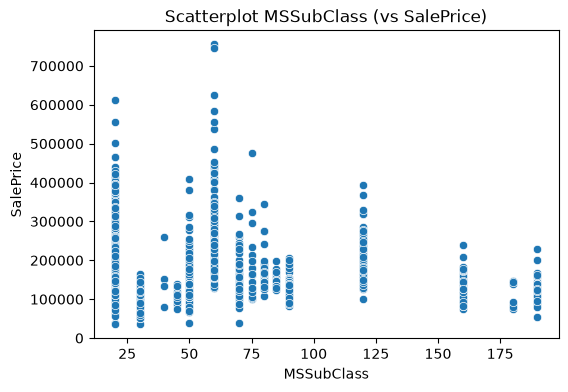

<Figure size 640x480 with 0 Axes>

In [84]:
## visualisasi outlier terbanyak terhadap SalePrice
outlier_top_features = info_outlier.sort_values(by='jumlah_outlier', ascending=False).head(5)['fitur'].tolist()
print(f"4 fitur dengan outlier terbanyak: {outlier_top_features}")

## vs saleprice
for col in outlier_top_features:
    plt.figure(figsize=(6, 4))
    sns.scatterplot(x=df[col], y=df['SalePrice'])
    plt.title(f'Scatterplot {col} (vs SalePrice)')
    plt.show()
plt.tight_layout()

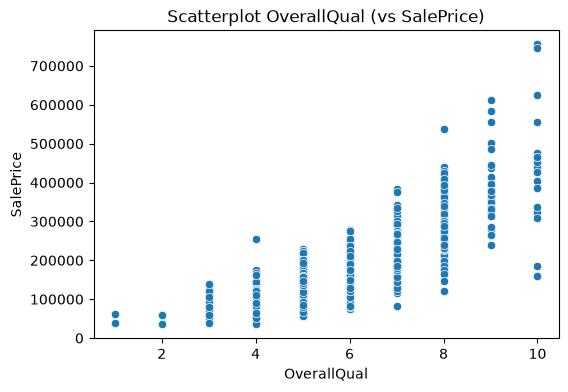

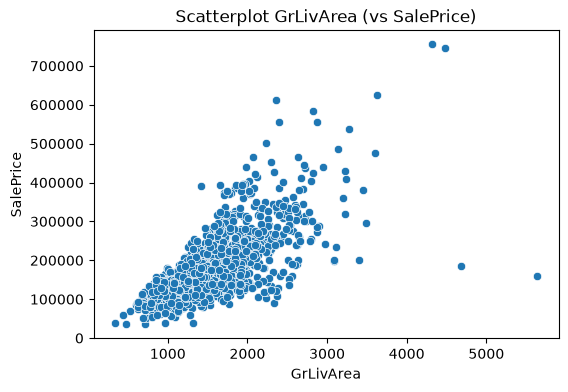

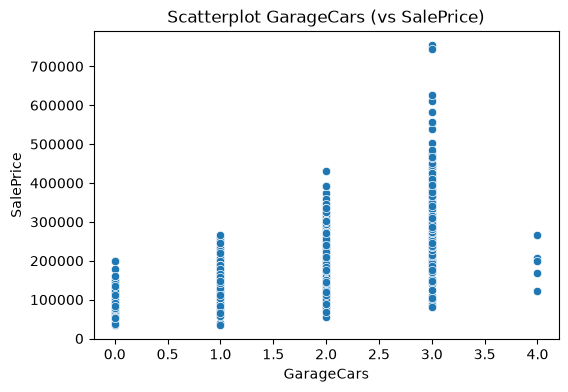

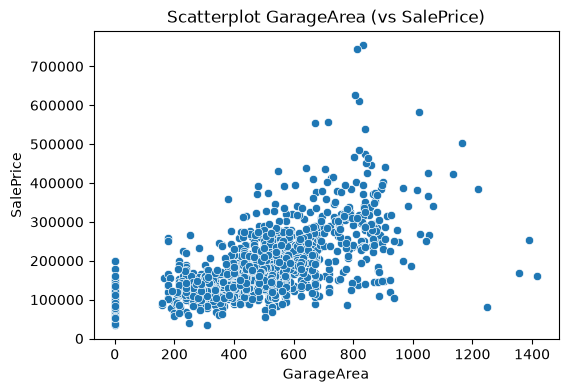

<Figure size 640x480 with 0 Axes>

In [85]:
## visualisasi fitur dengan corr tertinggi terhadap SalePrice dan lihat outlier
for col in top_features:
    plt.figure(figsize=(6, 4))
    sns.scatterplot(x=df[col], y=df['SalePrice'])
    plt.title(f'Scatterplot {col} (vs SalePrice)')
    plt.show()
plt.tight_layout()

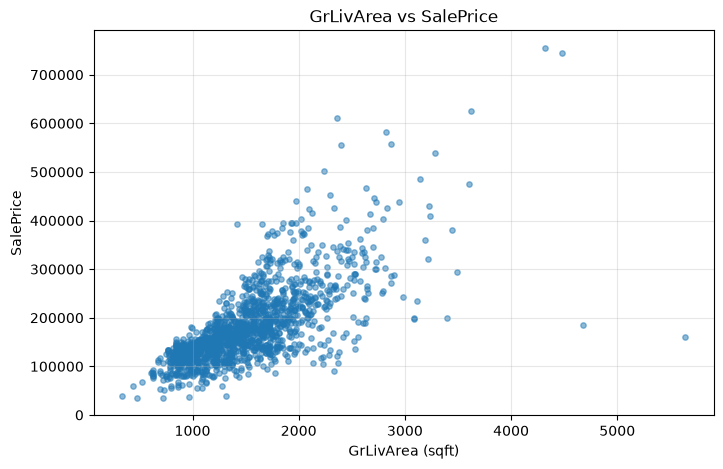

In [86]:
# Scatter plot GrLivArea vs SalePrice untuk melihat posisi outlier
plt.figure(figsize=(8, 5))
plt.scatter(df['GrLivArea'], df['SalePrice'], alpha=0.5, s=15)
plt.xlabel('GrLivArea (sqft)')
plt.ylabel('SalePrice')
plt.title('GrLivArea vs SalePrice')
plt.grid(True, alpha=0.3)
plt.show()


In [87]:
# Tampilkan data dengan GrLivArea > 4000
df[df['GrLivArea'] > 4000][['Id', 'GrLivArea', 'SalePrice', 'OverallQual']]


,Id,GrLivArea,SalePrice,OverallQual
523,524,4676,184750,10
691,692,4316,755000,10
1182,1183,4476,745000,10
1298,1299,5642,160000,10


In [88]:
# Hapus outlier yang teridentifikasi dari scatter plot:

# titik di pojok kanan bawah (luas > 4000 sqft, harga < 300000)
df = df[~((df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000))]
print(f"Jumlah data setelah penanganan outlier: {df.shape[0]}")


Jumlah data setelah penanganan outlier: 1458


## 4. Eksplorasi Fitur Numerik
Visualisasi korelasi linier antar variabel numerik menggunakan matriks korelasi.


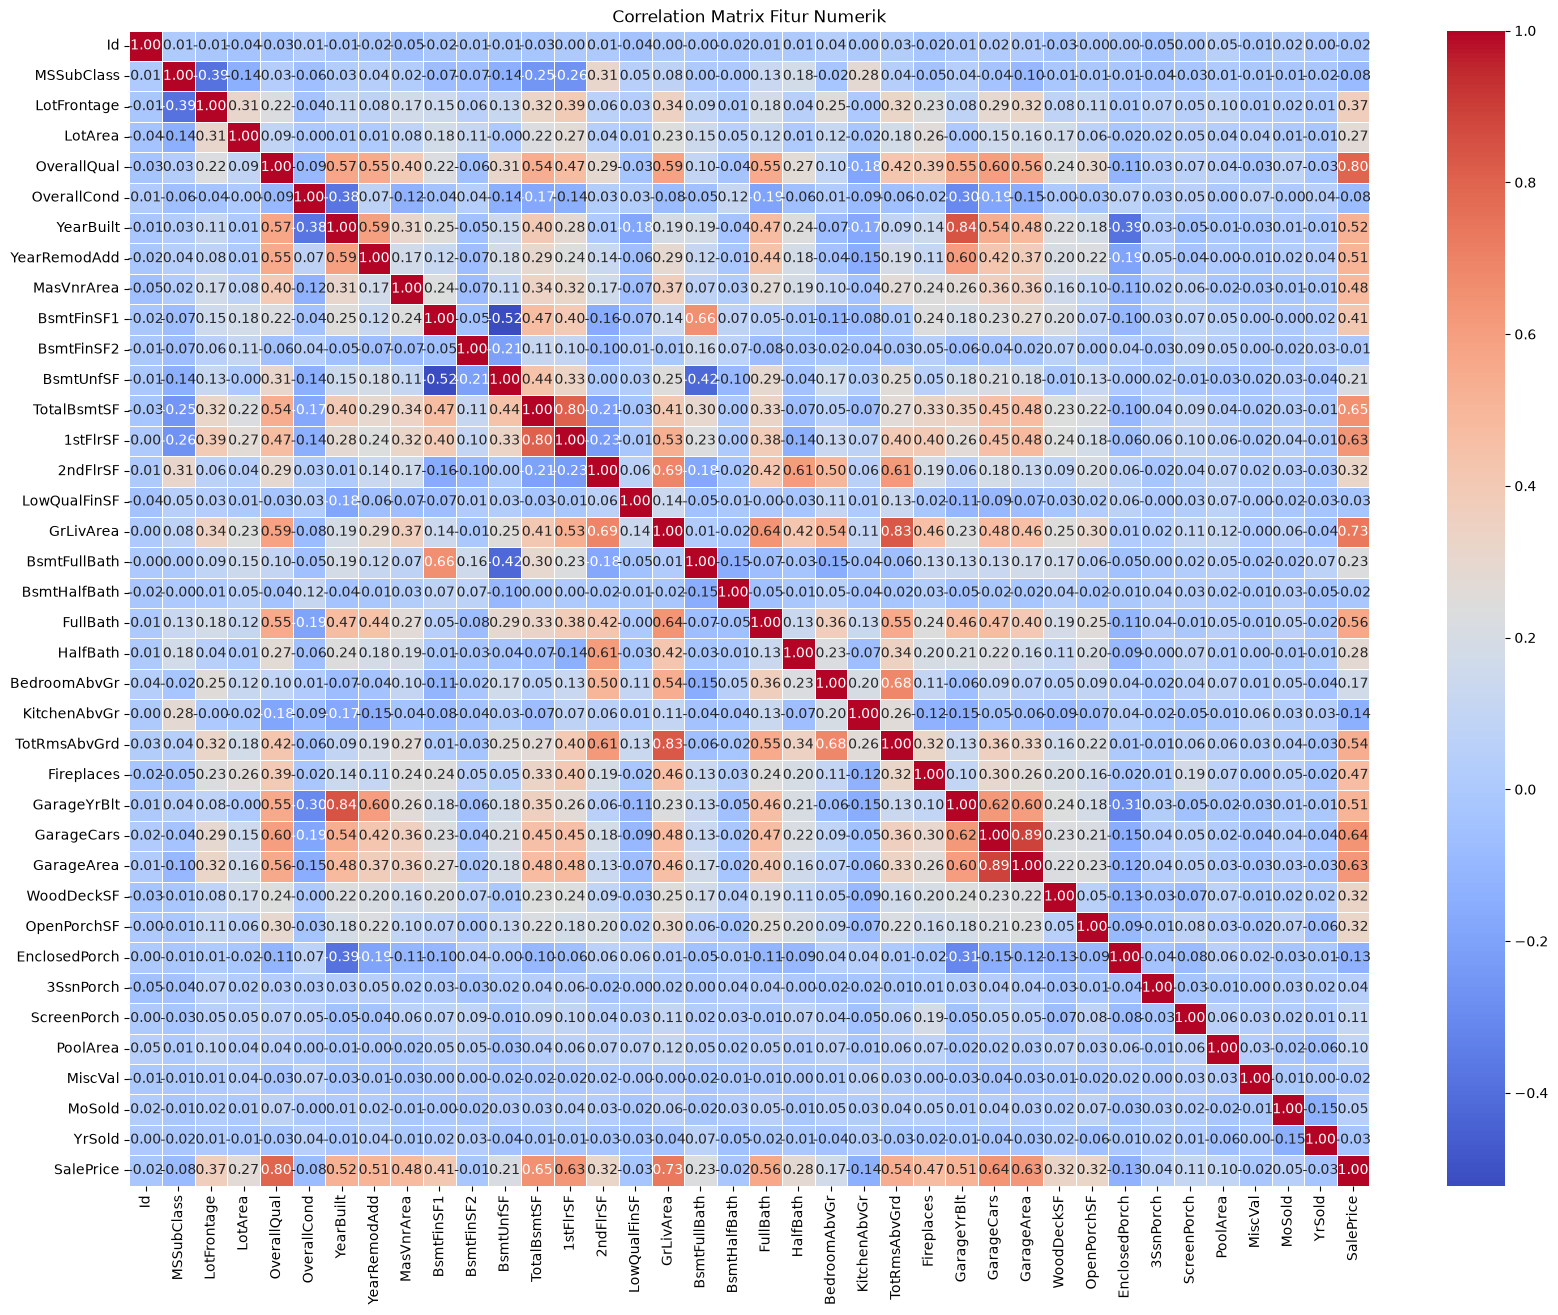

In [89]:
# Matriks korelasi antar seluruh fitur numerik
df_numeric = df.select_dtypes(include=['int64', 'float64'])

plt.figure(figsize=(20, 15))
sns.heatmap(df_numeric.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix Fitur Numerik')
plt.show()


## 5. Encoding Fitur Kategorikal
Tahapan encoding dibagi menjadi dua bagian:
1. **Manual Ordinal Encoding:** Untuk fitur dengan tingkatan hierarki alami sesuai dokumentasi data.
2. **Label Encoding:** Untuk sisa fitur kategorikal yang bertipe nominal.


### Pemetaan Skala Ordinal
* **Skala Kualitas dan Kondisi (Ex: 5, Gd: 4, TA: 3, Fa: 2, Po: 1, None: 0):** `ExterQual`, `ExterCond`, `BsmtQual`, `BsmtCond`, `HeatingQC`, `KitchenQual`, `FireplaceQu`, `GarageQual`, `GarageCond`, `PoolQC`
* **BsmtExposure:** `Gd`: 4, `Av`: 3, `Mn`: 2, `No`: 1, `None`: 0
* **BsmtFinType1 & BsmtFinType2:** `GLQ`: 6, `ALQ`: 5, `BLQ`: 4, `Rec`: 3, `LwQ`: 2, `Unf`: 1, `None`: 0
* **GarageFinish:** `Fin`: 3, `RFn`: 2, `Unf`: 1, `None`: 0
* **PavedDrive:** `Y`: 2, `P`: 1, `N`: 0
* **CentralAir:** `Y`: 1, `N`: 0
* **Functional:** `Typ`: 7, `Min1`: 6, `Min2`: 5, `Mod`: 4, `Maj1`: 3, `Maj2`: 2, `Sev`: 1, `Sal`: 0
* **LandSlope:** `Gtl`: 0, `Mod`: 1, `Sev`: 2
* **LotShape:** `Reg`: 3, `IR1`: 2, `IR2`: 1, `IR3`: 0


In [90]:
# 1. Standar kualitas & kondisi
qual_cond_map = {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}
qual_cols = [
    'ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
    'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC'
]
for col in qual_cols:
    df[col] = df[col].map(qual_cond_map)

# 2. Fitur spesifik basement
df['BsmtExposure'] = df['BsmtExposure'].map({'Gd': 4, 'Av': 3, 'Mn': 2, 'No': 1, 'None': 0})
bsmt_fin_map = {'GLQ': 6, 'ALQ': 5, 'BLQ': 4, 'Rec': 3, 'LwQ': 2, 'Unf': 1, 'None': 0}
df['BsmtFinType1'] = df['BsmtFinType1'].map(bsmt_fin_map)
df['BsmtFinType2'] = df['BsmtFinType2'].map(bsmt_fin_map)

# 3. Fitur garasi & akses jalan
df['GarageFinish'] = df['GarageFinish'].map({'Fin': 3, 'RFn': 2, 'Unf': 1, 'None': 0})
df['PavedDrive'] = df['PavedDrive'].map({'Y': 2, 'P': 1, 'N': 0})

# 4. Fungsionalitas, AC, kemiringan, dan bentuk lahan
df['CentralAir'] = df['CentralAir'].map({'Y': 1, 'N': 0})
df['Functional'] = df['Functional'].map({'Typ': 7, 'Min1': 6, 'Min2': 5, 'Mod': 4, 'Maj1': 3, 'Maj2': 2, 'Sev': 1, 'Sal': 0})
df['LandSlope'] = df['LandSlope'].map({'Gtl': 0, 'Mod': 1, 'Sev': 2})
df['LotShape'] = df['LotShape'].map({'Reg': 3, 'IR1': 2, 'IR2': 1, 'IR3': 0})


### Encoding Fitur Nominal
Menerapkan `LabelEncoder` pada sisa kolom bertipe object (fitur kategorikal tanpa hierarki nilai).


In [91]:
from sklearn.preprocessing import LabelEncoder

# Ambil seluruh fitur kategorikal nominal yang tersisa
nominal_features = df.select_dtypes(include=['object']).columns

le = LabelEncoder()
for col in nominal_features:
    df[col] = le.fit_transform(df[col].astype(str))

print(f"Total fitur nominal yang di-encode: {len(nominal_features)}")


Total fitur nominal yang di-encode: 24


/tmp/ipykernel_44918/6093275.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  nominal_features = df.select_dtypes(include=['object']).columns


## 6. Normalisasi Fitur (MinMaxScaler)
Transformasi seluruh fitur independen ke rentang [0, 1] agar skala data seragam untuk tahapan reduksi dimensi. Kolom `Id` dan target `SalePrice` tidak dinormalisasi.


In [92]:
from sklearn.preprocessing import MinMaxScaler

# Kolom fitur yang akan dinormalisasi (semua kecuali Id dan SalePrice)
cols_to_scale = df.columns.drop(['Id', 'SalePrice'])

# Normalisasi data
scaler = MinMaxScaler()
df_normalized = df.copy()
df_normalized[cols_to_scale] = scaler.fit_transform(df[cols_to_scale])

df_normalized.head()


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,0.235294,0.75,0.150685,0.033420,1.0,0.5,1.000000,1.0,0.0,...,0.0,0.0,1.0,0.25,0.0,0.090909,0.50,1.0,0.8,208500
1,2,0.000000,0.75,0.202055,0.038795,1.0,0.5,1.000000,1.0,0.0,...,0.0,0.0,1.0,0.25,0.0,0.363636,0.25,1.0,0.8,181500
2,3,0.235294,0.75,0.160959,0.046507,1.0,0.5,0.666667,1.0,0.0,...,0.0,0.0,1.0,0.25,0.0,0.727273,0.50,1.0,0.8,223500
3,4,0.294118,0.75,0.133562,0.038561,1.0,0.5,0.666667,1.0,0.0,...,0.0,0.0,1.0,0.25,0.0,0.090909,0.00,1.0,0.0,140000
4,5,0.235294,0.75,0.215753,0.060576,1.0,0.5,0.666667,1.0,0.0,...,0.0,0.0,1.0,0.25,0.0,1.000000,0.50,1.0,0.8,250000


## 7. Reduksi Dimensi (PCA) dan Evaluasi Performa
Evaluasi efektivitas reduksi dimensi menggunakan Principal Component Analysis (PCA) dengan variasi ambang variansi kumulatif (95%, 90%, 80%) dibandingkan baseline tanpa PCA. Model Linear Regression sederhana digunakan untuk mengukur skor $R^2$ pada data uji serta waktu komputasi pelatihan model.


In [93]:
import time
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score

# 1. Pemisahan fitur (X) dan target (y)
X = df_normalized.drop(columns=['Id', 'SalePrice'])
y = df['SalePrice']

# 2. Split data train dan test (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Definisi skenario pengujian
experiments = {
    'Tanpa PCA': (None, X_train, X_test),
    'PCA 95%': (PCA(n_components=0.95), None, None),
    'PCA 90%': (PCA(n_components=0.90), None, None),
    'PCA 80%': (PCA(n_components=0.80), None, None)
}

results = []

# 4. Eksekusi pengujian untuk tiap skenario
for name, (pca, x_tr, x_te) in experiments.items():
    if pca is not None:
        x_tr = pca.fit_transform(X_train)
        x_te = pca.transform(X_test)
        n_features = pca.n_components_
    else:
        n_features = x_tr.shape[1]
    
    # Pengukuran waktu pelatihan model
    t0 = time.time()
    model = LinearRegression()
    model.fit(x_tr, y_train)
    fit_time = time.time() - t0
    
    # Evaluasi prediksi pada data uji
    y_pred = model.predict(x_te)
    score_r2 = r2_score(y_test, y_pred)
    
    results.append({
        'Skenario': name,
        'Jumlah Fitur': n_features,
        'R2 Score (Test)': round(score_r2, 4),
        'Fit Time Taken (s)': round(fit_time, 4)
    })

df_evaluasi = pd.DataFrame(results)
df_evaluasi


,Skenario,Jumlah Fitur,R2 Score (Test),Fit Time Taken (s)
0,Tanpa PCA,79,0.8747,0.3449
1,PCA 95%,45,0.8486,0.1201
2,PCA 90%,33,0.8357,0.1599
3,PCA 80%,23,0.8246,0.0815


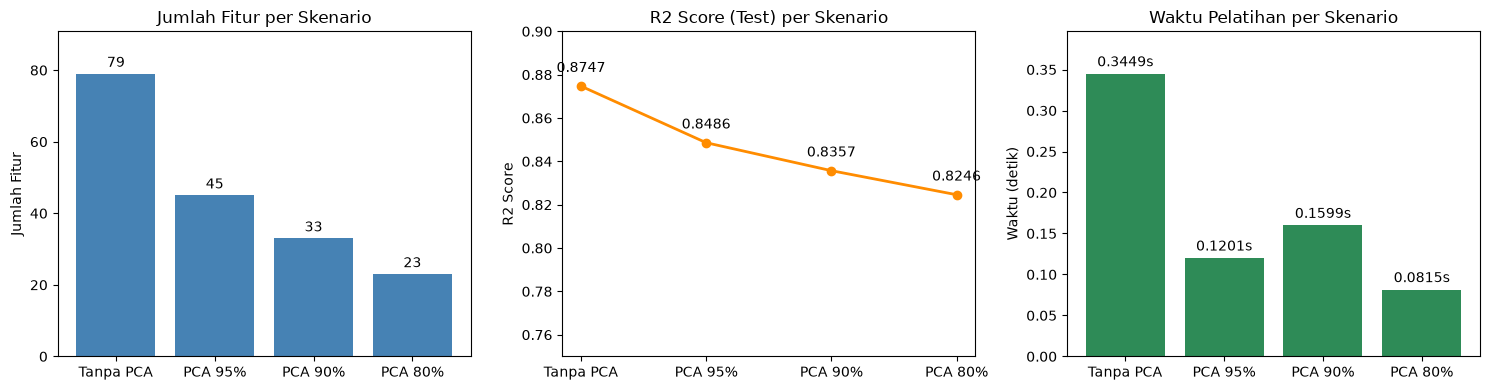

In [102]:
# Visualisasi perbandingan metrik evaluasi tiap parameter PCA
fig, axes = plt.subplots(1, 3, figsize=(15, 4))


# ============================================================
# 1. Bar plot: Jumlah Fitur
# ============================================================
bars1 = axes[0].bar(
    df_evaluasi['Skenario'],
    df_evaluasi['Jumlah Fitur'],
    color='steelblue'
)

axes[0].set_title('Jumlah Fitur per Skenario')
axes[0].set_ylabel('Jumlah Fitur')

axes[0].set_ylim(
    0,
    df_evaluasi['Jumlah Fitur'].max() * 1.15
)

for bar, v in zip(bars1, df_evaluasi['Jumlah Fitur']):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        v + 1,
        str(v),
        ha='center',
        va='bottom'
    )


# ============================================================
# 2. Line plot: R2 Score pada Data Uji
# ============================================================
axes[1].plot(
    df_evaluasi['Skenario'],
    df_evaluasi['R2 Score (Test)'],
    marker='o',
    color='darkorange',
    linewidth=2
)

axes[1].set_title('R2 Score (Test) per Skenario')
axes[1].set_ylabel('R2 Score')
axes[1].set_ylim(0.75, 0.90)

for i, v in enumerate(df_evaluasi['R2 Score (Test)']):
    axes[1].text(
        i,
        v + 0.005,
        f"{v:.4f}",
        ha='center',
        va='bottom'
    )


# ============================================================
# 3. Bar plot: Waktu Pelatihan Model
# ============================================================
bars3 = axes[2].bar(
    df_evaluasi['Skenario'],
    df_evaluasi['Fit Time Taken (s)'],
    color='seagreen'
)

axes[2].set_title('Waktu Pelatihan per Skenario')
axes[2].set_ylabel('Waktu (detik)')

axes[2].set_ylim(
    0,
    df_evaluasi['Fit Time Taken (s)'].max() * 1.15
)

for bar, v in zip(bars3, df_evaluasi['Fit Time Taken (s)']):
    axes[2].text(
        bar.get_x() + bar.get_width() / 2,
        v + 0.005,
        f"{v:.4f}s",
        ha='center',
        va='bottom'
    )


plt.tight_layout()
plt.show()